## Random Forest Model

In this section we build a random forest classifier to estimate the probability that a shot results in a goal, its expected goals (xG) value. Rather than predicting a simple goal/no goal outcome, the model outputs a probability between 0 and 1 for every shot. These probabilities can then be added up across a season, or for each team, and compared with the number of goals actually scored.

A random forest is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the training shots and, at each split, only considers a random subset of the features. For a new shot, every tree gives an estimate of the goal probability and the forest averages them. Averaging over many different trees reduces the instability of a single tree and makes the model less likely to overfit. Random forests also capture non-linear relationships and interactions between features without these being specified in advance. For example, the effect of shooting angle may depend on distance, and a header from close range behaves differently from a header further out.

The model is trained on shots from the 2021/22 to 2024/25 Premier League seasons and tested on the 2025/26 season, which is held out until the final evaluation. Hyperparameters are chosen using leave-one-season-out cross-validation on the training seasons, scored by log loss. Understat's own xG values [2] are not used as a feature; they are kept only as a benchmark to compare our model against.

The structure of this section, including fitting a single decision tree before the forest, follows the *Decision Trees & Random Forests* beginner workshop from the Bristol Data Science Society [1]. We adapt it from a pass/fail classification task to probability prediction, so performance is judged on the quality of the predicted probabilities rather than on accuracy.

### Libraries

We use pandas and NumPy for handling the data, matplotlib for plotting, and scikit-learn for the models, cross-validation and evaluation metrics. A fixed random seed (`RANDOM_STATE = 42`) is set so that the decision trees, random forests and cross-validation give the same results each time the notebook is run.

In [2]:
# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# Models
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Cross-validation and tuning
from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV

# Evaluation
from sklearn.metrics import brier_score_loss, log_loss

# Fix the random seed so results are the same every time the notebook is run
RANDOM_STATE = 42

### Loading and preparing the data

We load the cleaned Understat shot data for the Premier League. The 2026/27 season is incomplete, so we remove it and work with five full seasons (2021/22 to 2025/26).

Penalties are always taken from the same spot with no defenders, so the available features cannot tell one penalty from another. We keep them in the data (`DROP_PENALTIES = False`), so `is_penalty` is used as a feature and the model learns a separate probability for them. The switch allows them to be removed if needed.

In [3]:
# Load the cleaned shot data (change the file name/path if yours is different)
df = pd.read_csv("DST Understat shot data - cleaned.csv")

# Remove the incomplete 2026/27 season
df = df[df["season"] != "2026/27"].copy()

# Choose whether to keep penalties
DROP_PENALTIES = False

if DROP_PENALTIES:
    df = df[df["is_penalty"] == 0].copy()

print("Total shots:", len(df))
print("Overall goal rate:", round(df["result"].mean(), 4))

# Shots, goals and goal rate for each season
season_summary = df.groupby("season").agg(
    shots=("result", "size"),
    goals=("result", "sum"),
    goal_rate=("result", "mean"),
)
season_summary["goal_rate"] = season_summary["goal_rate"].round(4)
season_summary

Total shots: 49140
Overall goal rate: 0.109


,shots,goals,goal_rate
season,,,
2021/22,9741,1037,0.1065
2022/23,9598,1038,0.1081
2023/24,10474,1196,0.1142
2024/25,9844,1081,0.1098
2025/26,9483,1004,0.1059


The table shows that the goal rate is very stable across seasons, between 10.6% and 11.4%. This supports training on past seasons to predict a future one, since the basic chance of a shot being scored does not change much from year to year.

### Features and target

The target is `result`: 1 if the shot was a goal, 0 if not.

The features are everything that describes the shot itself: its position (`x`, `y`, `angle_to_goal`), body part, the type of play (open play, set piece, corner, free kick), the action before the shot, whether it was assisted, the match minute, home/away, and the score at the time.

We leave out three columns:
- `xg`: Understat's own xG, kept only as a benchmark. Using it as a feature would mean copying their model.
- `season`: used to split the data into training and test sets.
- `team`: so the model judges the quality of the shot, not who took it.

In [2]:
# Target: 1 = goal, 0 = no goal
target = "result"

# Columns that are not used as features
excluded = ["result", "xg", "season", "team"]

# Features: every other column
features = [col for col in df.columns if col not in excluded]

print("Number of features:", len(features))
print(features)

NameError: name 'df' is not defined

### Train/test split by season

Instead of splitting the shots at random, we split them by season. The model is trained on 2021/22 to 2024/25 and tested on 2025/26. This mirrors how an xG model would be used in practice: built on past seasons and applied to a new one. It also means the test shots come from matches the model has never seen.

The 2025/26 season is kept aside until the final evaluation. Hyperparameters will be chosen using cross-validation on the training seasons only, so the test set gives an honest measure of performance.

In [1]:
# Training seasons and test season
train_seasons = ["2021/22", "2022/23", "2023/24", "2024/25"]
test_season = "2025/26"

train = df[df["season"].isin(train_seasons)]
test = df[df["season"] == test_season]

# Features (X) and target (y)
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# Season labels for the training shots, used later for leave-one-season-out CV
groups_train = train["season"]

# Understat's xG for the test shots, kept as a benchmark
understat_xg_test = test["xg"]

print("Training shots:", len(X_train), "| goal rate:", round(y_train.mean(), 4))
print("Test shots:    ", len(X_test), "| goal rate:", round(y_test.mean(), 4))

NameError: name 'df' is not defined

### A single decision tree

Before building the forest, we fit a single decision tree of depth 3, small enough to read, to see how shots are split. The predicted xG for a shot is the proportion of training shots in its final group (leaf) that were goals: if 60 of 300 shots in a leaf were goals, any shot reaching that leaf gets an xG of 0.20.

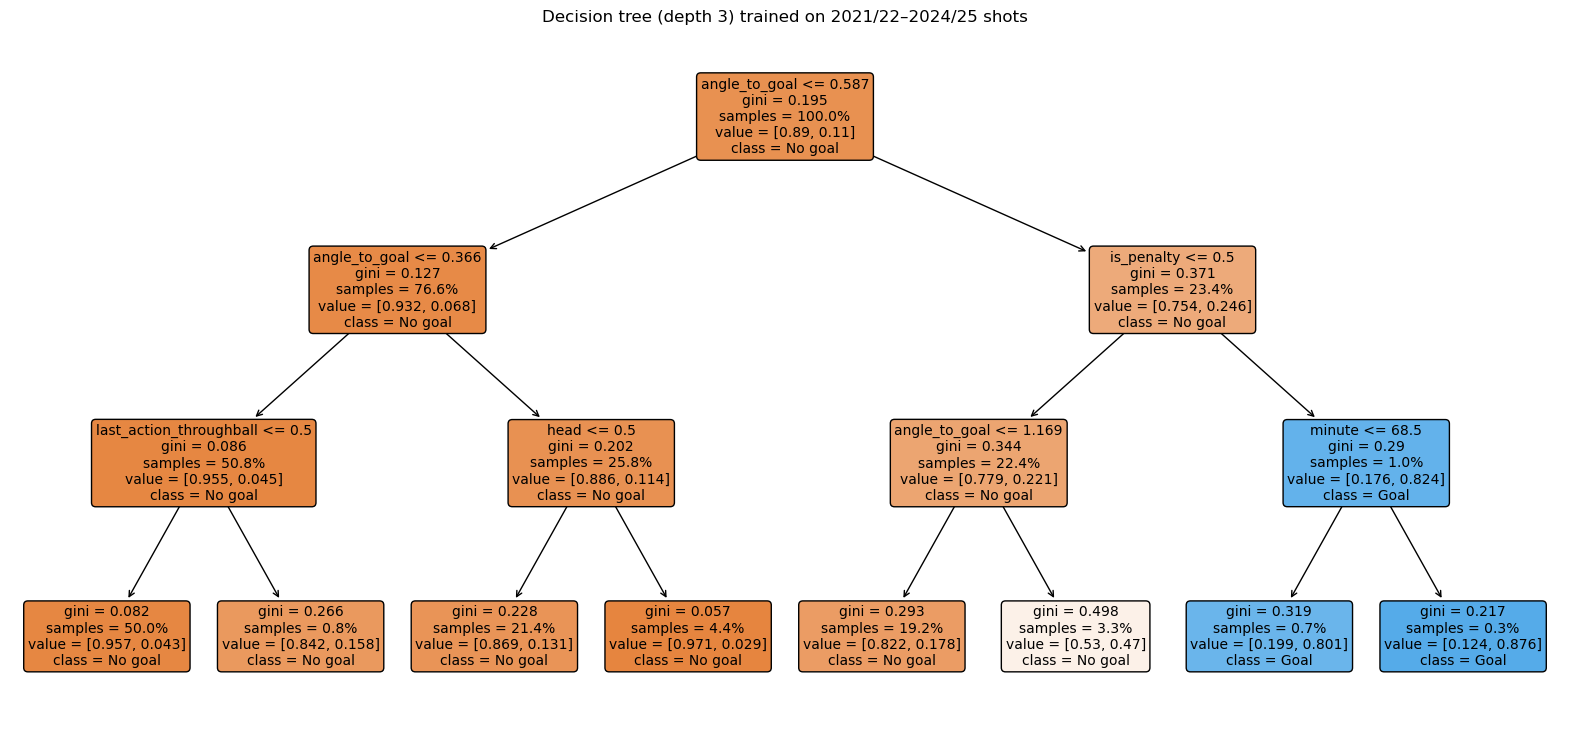

In [6]:
# Fit a small decision tree (depth 3 so it is readable)
tree_model = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)

# Plot the tree
plt.figure(figsize=(20, 9))
plot_tree(
    tree_model,
    feature_names=features,
    class_names=["No goal", "Goal"],
    filled=True,
    rounded=True,
    proportion=True,   # show the share of goals in each box, i.e. the xG
    fontsize=10,
)
plt.title("Decision tree (depth 3) trained on 2021/22–2024/25 shots")
plt.show()

The first split is on `angle_to_goal`, the angle of the goal visible from the shot position. This combines distance and how central the shot is, so it is the most informative single feature. For example, a non-penalty shot with a wide angle (above 1.17) reaches a leaf where 606 of 1,290 shots were goals, giving an xG of 0.47. A narrow-angle shot that was not from a through ball gets an xG of only 0.043.

The tree also separates penalties, which get an xG of around 0.8. It then splits penalties by match minute (0.80 before the 69th minute, 0.88 after). This is almost certainly noise from a small number of shots, a simple example of a tree fitting patterns that will not hold for new data.

Because a depth-3 tree has only 8 leaves, it can only give 8 different xG values. Every shot gets one of these few numbers, which is far too crude for xG. This motivates the random forest: averaging many different trees gives a smooth range of probabilities.

In [7]:
# Predicted probability of a goal for each training shot
tree_xg = tree_model.predict_proba(X_train)[:, 1]

print("Number of different xG values the tree can give:", len(np.unique(tree_xg)))
print(np.round(np.unique(tree_xg), 3))

Number of different xG values the tree can give: 8
[0.029 0.043 0.131 0.158 0.178 0.47  0.801 0.876]


### A basic random forest

We start with reasonable settings, which are tuned with cross-validation in the next section:
- `n_estimators=300`: 300 trees.
- `min_samples_leaf=20`: every leaf must contain at least 20 shots. Without this, trees can grow leaves containing a single shot, which give probabilities of exactly 0 or 1.

To check the forest without touching the test season, we use out-of-bag (OOB) predictions. Each tree never sees roughly a third of the training shots, so each shot can be predicted using only the trees that did not train on it. This gives an honest estimate of performance on unseen shots.

In [8]:
# Basic random forest with starting settings
rf_basic = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=20,
    oob_score=True,          # keep out-of-bag predictions
    n_jobs=-1,               # use all CPU cores
    random_state=RANDOM_STATE,
)
rf_basic.fit(X_train, y_train)

# Out-of-bag xG: each shot predicted only by trees that did not see it
oob_xg = rf_basic.oob_decision_function_[:, 1]

print("Different xG values given:", len(np.unique(oob_xg)))
print("OOB Brier score:", round(brier_score_loss(y_train, oob_xg), 4))
print("OOB log loss:   ", round(log_loss(y_train, oob_xg), 4))
print("Understat Brier on the same shots:", round(brier_score_loss(y_train, train["xg"]), 4))

Different xG values given: 39657
OOB Brier score: 0.0803
OOB log loss:    0.2818
Understat Brier on the same shots: 0.0757


The forest gives a different xG value to every one of the 39,657 training shots, compared with only 8 values from the single tree.

Its out-of-bag Brier score is 0.0803 and its log loss is 0.2818. Understat's xG scores 0.0757 on the same shots, so this basic forest is clearly better than guessing but not yet as good as Understat. This is before any tuning, and Understat’s model may use information that is not in our data.

In [9]:
# A few example shots: forest xG vs Understat xG vs what happened
examples = pd.DataFrame({
    "x": train["x"].values,
    "y": train["y"].values,
    "header": train["head"].values,
    "forest_xg": oob_xg.round(3),
    "understat_xg": train["xg"].values.round(3),
    "goal": y_train.values,
}).sample(10, random_state=RANDOM_STATE)

examples

,x,y,header,forest_xg,understat_xg,goal
19138,110.519998,59.120001,0,0.042,0.022,0
32705,107.039996,33.120001,1,0.020,0.014,0
36343,95.880002,48.160001,0,0.050,0.038,0
19125,90.600000,27.679999,0,0.032,0.019,0
27107,104.639996,48.720001,0,0.124,0.083,0
8929,87.239996,43.120001,0,0.020,0.019,0
23573,93.360004,52.400000,0,0.023,0.021,0
26354,102.480002,41.120001,0,0.152,0.130,0
13687,106.560004,27.039999,0,0.147,0.318,1
32683,90.839996,52.400000,0,0.026,0.020,0


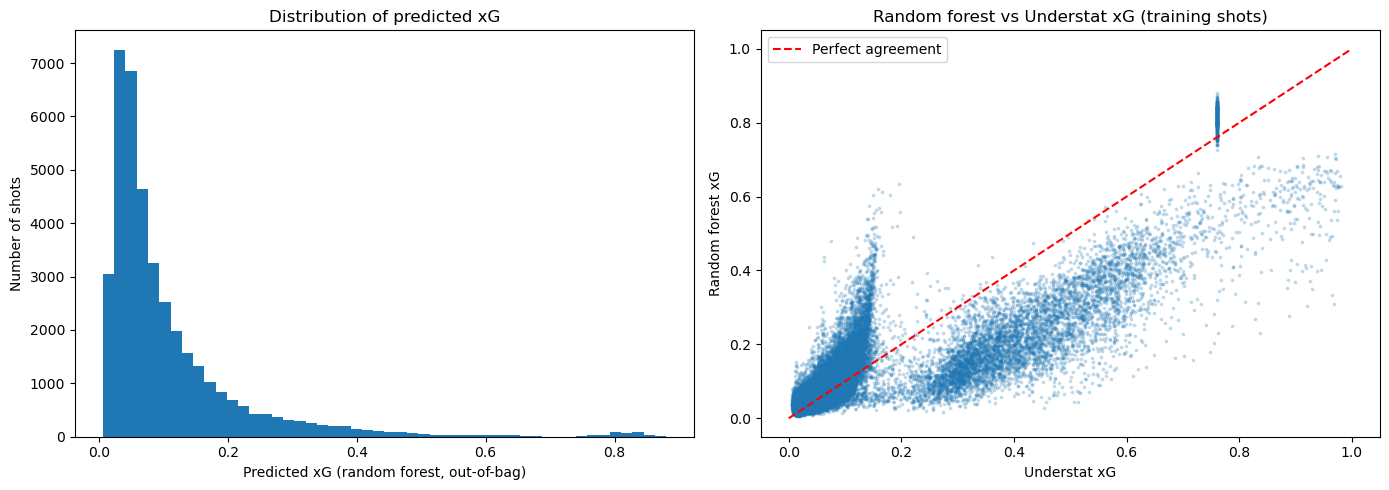

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of predicted xG
axes[0].hist(oob_xg, bins=50)
axes[0].set_xlabel("Predicted xG (random forest, out-of-bag)")
axes[0].set_ylabel("Number of shots")
axes[0].set_title("Distribution of predicted xG")

# Forest xG vs Understat xG
axes[1].scatter(train["xg"], oob_xg, s=3, alpha=0.2)
axes[1].plot([0, 1], [0, 1], color="red", linestyle="--", label="Perfect agreement")
axes[1].set_xlabel("Understat xG")
axes[1].set_ylabel("Random forest xG")
axes[1].set_title("Random forest vs Understat xG (training shots)")
axes[1].legend()

plt.tight_layout()
plt.show()

The histogram is heavily skewed: most shots have a low predicted xG, with a long tail of better chances and a small cluster around 0.8 from penalties.

The scatter shows the forest broadly agrees with Understat (correlation of about 0.84) but compresses the extremes: the forest's highest xG is 0.88, compared with 0.98 for Understat. This is because the forest averages over many trees and leaves of at least 20 shots, which pulls very high predictions towards the middle. The vertical streak at an Understat xG of about 0.76 is the penalties: Understat gives every penalty the same value, while the forest gives them a range of about 0.75 to 0.88.

### Hyperparameter tuning with cross-validation

We tune three settings of the random forest: `max_depth` (how deep each tree can grow), `min_samples_leaf` (the minimum number of shots in each leaf) and `max_features` (how many features each split can choose from). Every combination is tested with leave-one-season-out cross-validation on the four training seasons. In each of four folds, the forest is trained on three seasons and predicts the fourth, which it has never seen. The 2025/26 test season is not used here. Combinations are ranked by log loss, and the Brier score is recorded alongside. We use 200 trees during tuning to keep the run time manageable.

The approach follows the cross-validation workshop from the Data Science Toolbox unit [3] and uses scikit-learn's `LeaveOneGroupOut` and `GridSearchCV` [4]. Whole seasons are held out rather than random shots, so the validation shots come from matches the model has not seen.

In [11]:
param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [10, 25, 50, 100],
    "max_features": ["sqrt", 0.5],
}

# Leave-one-season-out: 4 folds, each holds out one training season
logo = LeaveOneGroupOut()

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=logo,
    scoring={"log_loss": "neg_log_loss", "brier": "neg_brier_score"},
    refit="log_loss",            # choose the best settings by log loss
    return_train_score=True,     # also record training scores for comparison
    n_jobs=-1,
)

grid_search.fit(X_train, y_train, groups=groups_train)

print("Best settings:", grid_search.best_params_)
print("Best CV log loss:", round(-grid_search.best_score_, 4))

Best settings: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 50}
Best CV log loss: 0.2821


In [12]:
cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = pd.DataFrame({
    "max_depth": cv_results["param_max_depth"],
    "min_samples_leaf": cv_results["param_min_samples_leaf"],
    "max_features": cv_results["param_max_features"],
    "cv_log_loss": -cv_results["mean_test_log_loss"],
    "cv_brier": -cv_results["mean_test_brier"],
    "train_log_loss": -cv_results["mean_train_log_loss"],
}).sort_values("cv_log_loss")

results_table.round(4).head(10)

,max_depth,min_samples_leaf,max_features,cv_log_loss,cv_brier,train_log_loss
14,10,50,0.5,0.2821,0.0802,0.2655
13,10,25,0.5,0.2822,0.0802,0.2595
12,10,10,0.5,0.2823,0.0802,0.2516
16,15,10,sqrt,0.2824,0.0803,0.2458
15,10,100,0.5,0.2824,0.0804,0.2711
22,15,50,0.5,0.2825,0.0802,0.2578
23,15,100,0.5,0.2826,0.0804,0.2680
31,None,100,0.5,0.2826,0.0804,0.2677
30,None,50,0.5,0.2827,0.0803,0.2561
25,None,25,sqrt,0.2827,0.0805,0.2586


In [13]:
best_row = cv_results.loc[grid_search.best_index_]
print("Mean CV log loss:", round(-best_row["mean_test_log_loss"], 4))
print("Std across the 4 held-out seasons:", round(best_row["std_test_log_loss"], 4))

Mean CV log loss: 0.2821
Std across the 4 held-out seasons: 0.0061


The best combination is `max_depth=10`, `min_samples_leaf=50` and `max_features=0.5`, with a cross-validated log loss of 0.2821 and a Brier score of 0.0802. The top ten combinations differ by only 0.0006 in log loss, while the log loss of the best setting varies by 0.0061 (standard deviation) between the four held-out seasons. The differences between these settings are therefore smaller than the normal season-to-season variation, so the exact choice matters little. We use the best-scoring combination for the final model.

### Final model and 2025/26 predictions

We refit the forest on all four training seasons using the best settings from cross-validation (`max_depth=10`, `min_samples_leaf=50`, `max_features=0.5`). The number of trees is raised to 500, since more trees only make the averaged probabilities more stable. The model then predicts an xG value for every shot in the 2025/26 season. This is the first and only time the test season is used.

In [14]:
best = grid_search.best_params_

final_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=best["max_depth"],
    min_samples_leaf=best["min_samples_leaf"],
    max_features=best["max_features"],
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
final_rf.fit(X_train, y_train)

# xG for every 2025/26 shot
test_xg = final_rf.predict_proba(X_test)[:, 1]

# Table of predictions, kept for the group comparison
predictions = test[["season", "team", "is_penalty"]].copy()
predictions["rf_xg"] = test_xg
predictions["understat_xg"] = understat_xg_test.values
predictions["goal"] = y_test.values

predictions.head()

,season,team,is_penalty,rf_xg,understat_xg,goal
39657,2025/26,Liverpool,0,0.021962,0.014601,0
39658,2025/26,Liverpool,0,0.036348,0.042656,0
39659,2025/26,Liverpool,0,0.164594,0.257975,0
39660,2025/26,Liverpool,0,0.063644,0.077662,0
39661,2025/26,Liverpool,0,0.221226,0.404091,1


In [15]:
# Constant baseline: every shot gets the training-season goal rate
baseline = np.full(len(y_test), y_train.mean())

scores = pd.DataFrame(
    {
        "Brier score": [
            brier_score_loss(y_test, test_xg),
            brier_score_loss(y_test, understat_xg_test),
            brier_score_loss(y_test, baseline),
        ],
        "Log loss": [
            log_loss(y_test, test_xg),
            log_loss(y_test, understat_xg_test),
            log_loss(y_test, baseline),
        ],
    },
    index=["Random forest", "Understat xG", "Constant (training goal rate)"],
)
display(scores.round(5))

print("Actual goals in 2025/26:      ", int(y_test.sum()))
print("Random forest total xG:       ", round(test_xg.sum(), 1))
print("Understat total xG:           ", round(understat_xg_test.sum(), 1))

,Brier score,Log loss
Random forest,0.07885,0.27904
Understat xG,0.07561,0.26711
Constant (training goal rate),0.09468,0.33788


Actual goals in 2025/26:       1004
Random forest total xG:        1063.4
Understat total xG:            1183.9


In [20]:
predictions.insert(0, "row_id", predictions.index)  # row number in the cleaned CSV
predictions.to_csv("rf_xg_predictions_2025_26.csv", index=False)

On the held-out 2025/26 season, the random forest scores a Brier score of 0.0789 and a log loss of 0.2790. This is much better than giving every shot the same probability (0.0947 and 0.3379), and not far behind Understat's own xG (0.0756 and 0.2671). Measured on both scores, the forest closes roughly 83% of the gap between the constant baseline and Understat. The two metrics rank the models in the same order, so the conclusion does not depend on which one we use.

The season totals tell a different story. There were 1,004 goals in 2025/26. The forest's xG sums to 1,063 (5.9% too high), while Understat's sums to 1,184 (17.9% too high). On totals alone the forest looks clearly better than Understat, yet Understat gives better probabilities shot by shot. This is a known weakness of judging an xG model by its total alone: over- and under-predictions on different shots cancel out, so a total can be close even when individual predictions are weaker. Totals check whether the overall level is right, and the per-shot scores check whether each shot gets a sensible probability, so both are needed.

This is a single season of 9,483 shots, and the season-to-season variation in log loss found during cross-validation (a standard deviation of 0.0061) is not small compared with the 0.012 gap to Understat, so we should not over-interpret the exact size of the gap.

### Which features does the forest use?

The forest records how much each feature reduces impurity (mixing of goals and non-goals) across all its splits. The chart shows the ten most important features. This measure favours features with many distinct values, such as `x` and `angle_to_goal`, so it is best read as a rough guide rather than an exact ranking.

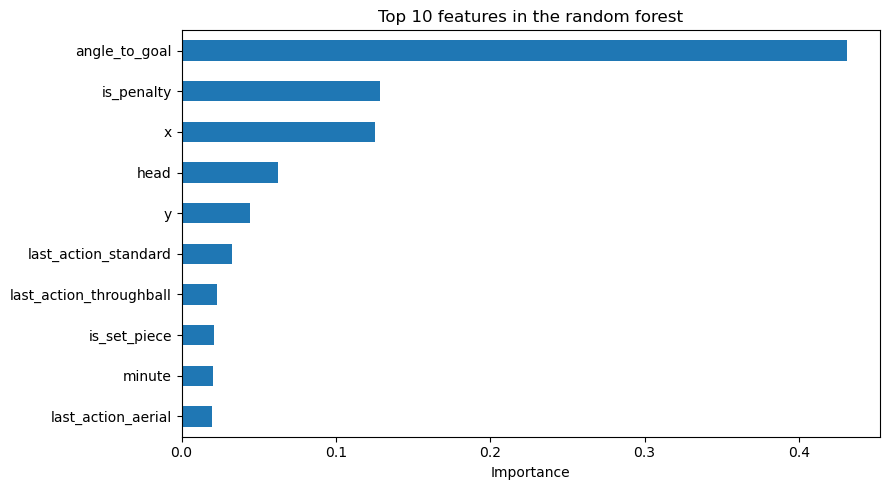

In [17]:
importance = pd.Series(final_rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 10 features in the random forest")
plt.tight_layout()
plt.show()

`angle_to_goal` is by far the most important feature (about 43% of the total), followed by `is_penalty` and the shot's distance along the pitch, `x` (about 13% each). The top three features together account for roughly 69%. This matches football intuition: how good a chance is depends mostly on how close and how central the shot is, with penalties a special case. Details such as body part, the previous action and the match minute contribute only a little each.

### Team totals

Expected goals are often used to judge teams over a season, so we compare each team's total predicted xG in 2025/26 with the goals it actually scored. As a reference, we also include a model that gives every shot the same probability (the training-season goal rate), so a team's total for that model is just its number of shots multiplied by a constant.

In [18]:
# Add the constant model to a copy of the predictions
team_df = predictions.copy()
team_df["constant_xg"] = y_train.mean()

team_totals = team_df.groupby("team").agg(
    shots=("goal", "size"),
    actual_goals=("goal", "sum"),
    rf_xg=("rf_xg", "sum"),
    understat_xg=("understat_xg", "sum"),
    constant_xg=("constant_xg", "sum"),
).round(1)

# Average error per team, in goals
for col in ["rf_xg", "understat_xg", "constant_xg"]:
    err = team_totals[col] - team_totals["actual_goals"]
    print(f"{col:14s} mean absolute error per team: {err.abs().mean():.1f} goals")

team_totals.sort_values("actual_goals", ascending=False)

rf_xg          mean absolute error per team: 4.4 goals
understat_xg   mean absolute error per team: 9.0 goals
constant_xg    mean absolute error per team: 4.3 goals


,shots,actual_goals,rf_xg,understat_xg,constant_xg
team,,,,,
Manchester City,593,74,72.1,81.2,65.1
Arsenal,552,66,69.2,79.0,60.6
Manchester United,596,66,66.4,74.2,65.4
Liverpool,584,61,58.6,67.8,64.1
Bournemouth,525,57,61.8,68.7,57.6
Chelsea,509,57,64.5,73.5,55.9
Aston Villa,482,53,49.6,58.5,52.9
Brentford,406,53,56.2,66.6,44.6
Newcastle United,492,53,56.5,63.1,54.0


Across the 20 teams, the random forest's total xG is off by 4.4 goals on average, compared with 9.0 for Understat. Understat's xG is too high for every team, which is the same over-prediction seen in the season total. The forest has no such consistent bias.

However, the constant model, which knows nothing about shot quality, is off by 4.3 goals, no better and no worse than the forest. This is because a team's total depends mainly on how many shots it takes, and the constant model already knows that. Team totals therefore cannot tell us whether the forest separates good chances from poor ones. That is what the per-shot Brier score and log loss measure, and there the forest is clearly better than the constant model (0.0789 against 0.0947). Judging an xG model on totals alone, at season or team level, would have hidden this.

### Limitations

A random forest predicts by averaging the goal rates of groups of similar training shots, so it cannot give a probability outside what it has seen in training, and averaging pulls the most extreme chances towards the middle (the forest's highest xG is 0.88, compared with 0.98 for Understat). Tuning made little difference: the top settings differed by much less than the normal season-to-season variation, which suggests the performance is limited by the information in the features rather than by the model's settings. The data has no goalkeeper or defender positions, which are likely part of why the forest trails Understat on a shot-by-shot basis. Finally, the model is tested on a single season of 9,483 shots, so the exact size of the gap to Understat should be treated with some caution.

### References

[1] Bristol Data Science Society *Workshop 1: Decision Trees & Random Forests (Beginner)*, Jupyter notebook. 

[2] Understat, shot-level expected goals data, https://understat.com

[3] Data Science Toolbox, *02.3 Regression and Cross-Validation Workshop*, course workshop materials.

[4] scikit-learn documentation, *Cross-validation: evaluating estimator performance*, https://scikit-learn.org/stable/modules/cross_validation.html